<a href="https://colab.research.google.com/github/TheAmirHK/AdeQuaT_Project_AI-and-Optimization/blob/main/SurrogateModelling/Output_f(Inputs).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import pickle
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score

In [2]:
# In[import data]

# Load the 1day data
file_path = r"1day.xlsx" # 24 Hours of production simulated data
df = pd.read_excel(file_path)

# Define input & output variables
input_vars = ['Anode reusing rate', 'Anode wasting rate', 'Cathode reusing rate', 'Cathode wasting rate', 'Cell rejection rate', 'Cell repairing rate', 'Cell scrap rate']
output_vars = ['Output ratio', 'Cell waste ratio', 'Cell repaired ratio', 'Cell recycled ratio', 'Anode slury waste ratio', 'Anode slury reused ratio', 'Cathode slury waste ratio', 'Cathode slury reused ratio']


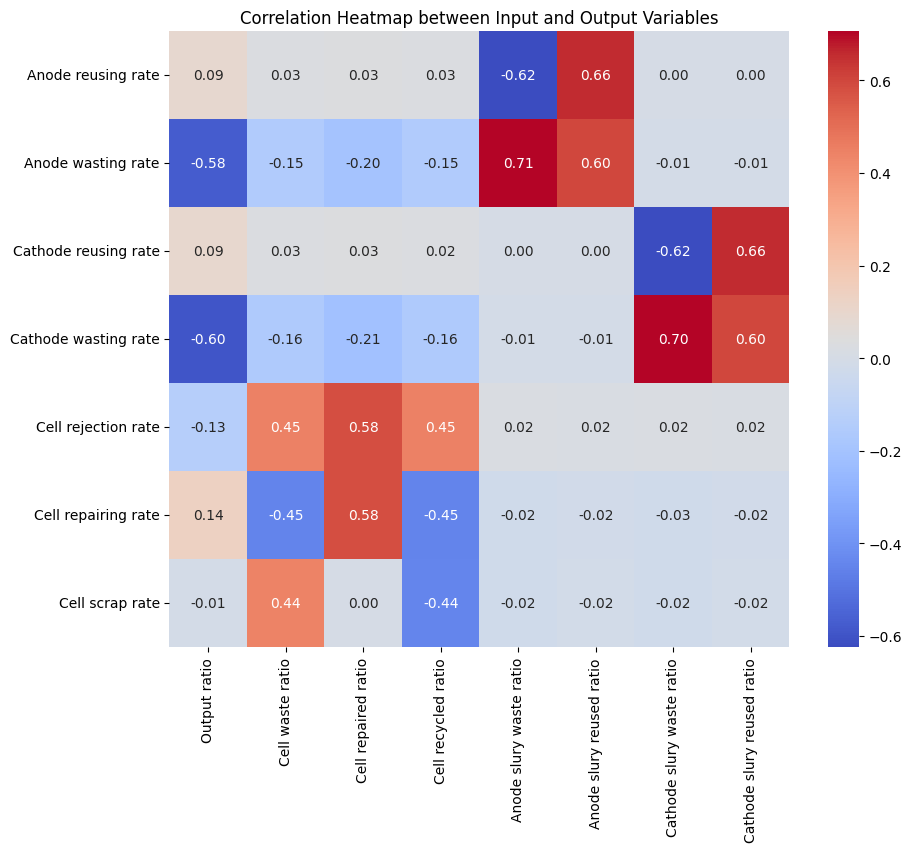

In [7]:
# In[plotting heatmap]

correlation_df = df[input_vars + output_vars]
correlation_matrix = correlation_df.corr()
input_output_correlation = correlation_matrix.loc[input_vars, output_vars]

plt.figure(figsize=(10, 8))
sns.heatmap(input_output_correlation, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap between Input and Output Variables')
plt.show()

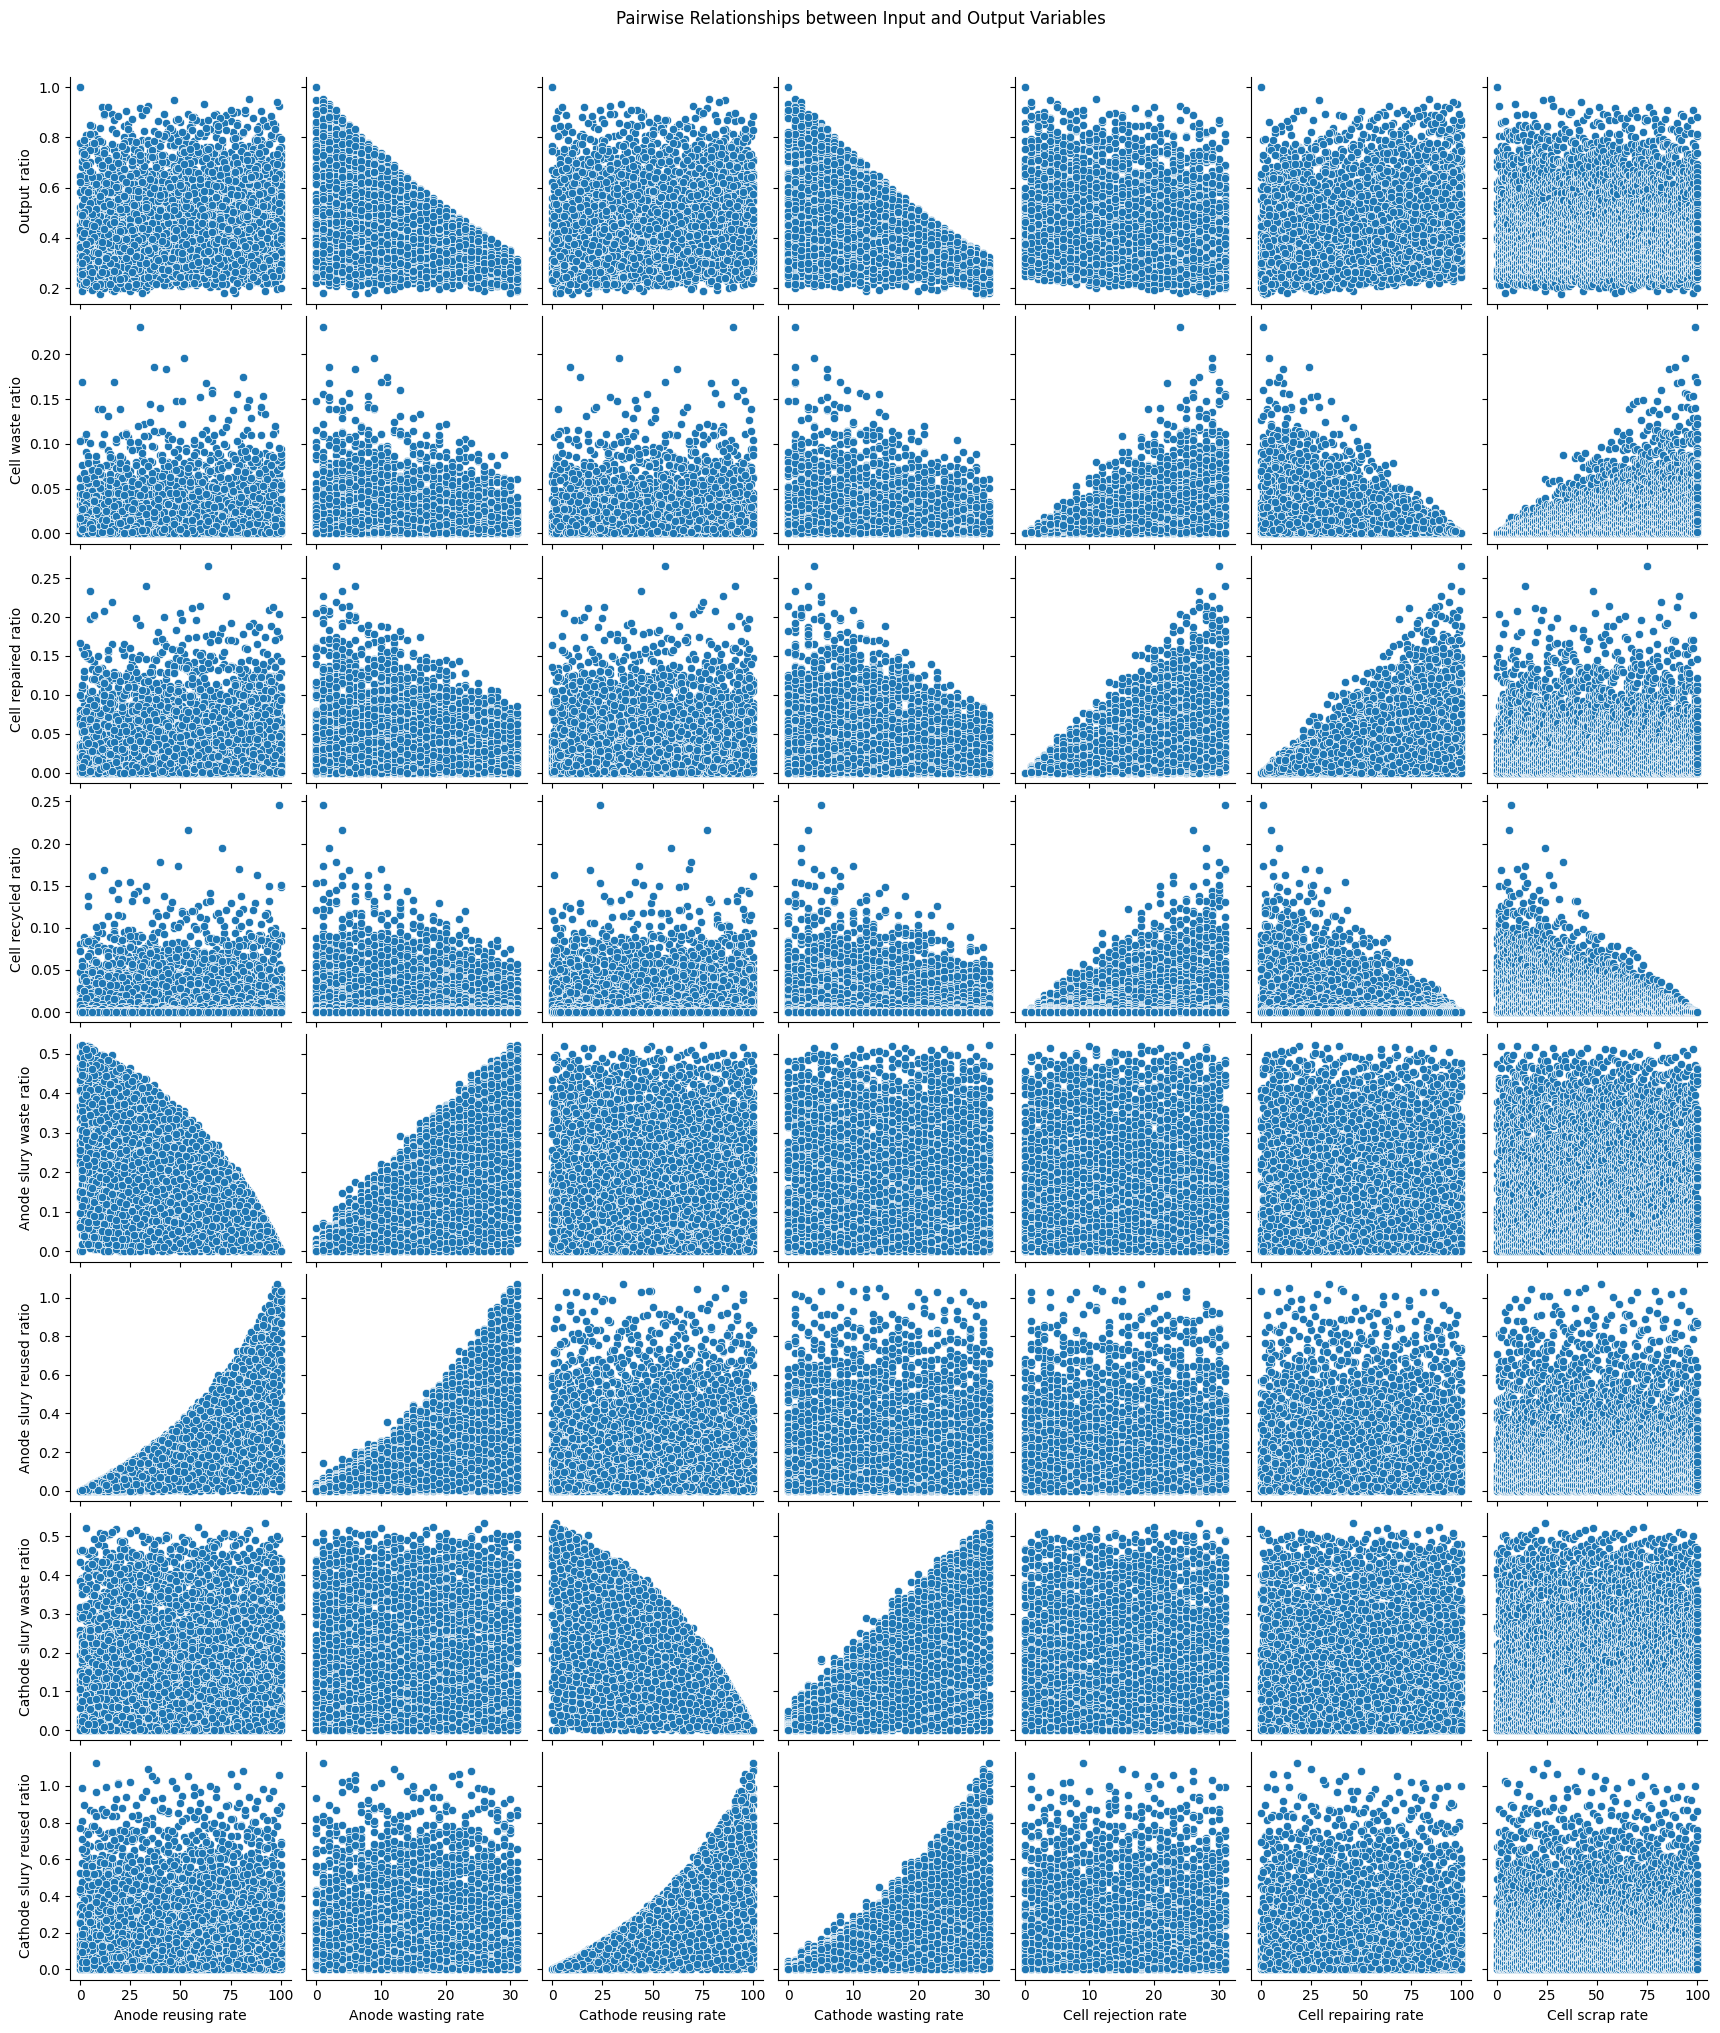

In [6]:
# In[generate a pairplot]

sns.pairplot(df, x_vars=input_vars, y_vars=output_vars)
plt.suptitle('Pairwise Relationships between Input and Output Variables', y=1.02)
plt.show()

In [ ]:
def fit_and_plot_models(df, input_var_name, output_var_name):

    input_var = df[input_var_name]
    output_var = df[output_var_name]

    data = pd.DataFrame({input_var_name: input_var, output_var_name: output_var}).dropna()

    input_cleaned = data[input_var_name]
    output_cleaned = data[output_var_name]

    def polynomial_model(x, a, b, c):
        return a * x**2 + b * x + c

    def logarithmic_model(x, a, b, c):
        return a * np.log(x + c) + b

    def power_law_model(x, a, b, c):
        return a * x**(-b) + c

    def exponential_decay_model(x, a, b, c):
        return a * np.exp(-b * x) + c

    plt.figure(figsize=(12, 8))
    sns.scatterplot(x=input_cleaned, y=output_cleaned, label="Data")

    models = {
        "Polynomial": polynomial_model,
        "Logarithmic": logarithmic_model,
        "Power Law": power_law_model,
        "Exponential Decay": exponential_decay_model
    }

    results = {}
    parameters = {}

    for name, model in models.items():
        try:
            if name == "Polynomial":
                 initial_guess = [0, 0, 1]
            elif name == "Logarithmic":
                 initial_guess = [-0.1, max(output_cleaned), min(input_cleaned) + 1e-6]

            elif name == "Power Law":
                 initial_guess = [max(output_cleaned), 0.5, min(output_cleaned)]
            elif name == "Exponential Decay":
                 initial_guess = [max(output_cleaned) - min(output_cleaned), 0.01, min(output_cleaned)]

            popt, pcov = curve_fit(model, input_cleaned, output_cleaned, p0=initial_guess, maxfev=5000)
            x_fit = np.linspace(min(input_cleaned), max(input_cleaned), 100)
            y_fit = model(x_fit, *popt)
            sns.lineplot(x=x_fit, y=y_fit, label=f"{name} Fit")

            y_pred = model(input_cleaned, *popt)
            r2 = r2_score(output_cleaned, y_pred)
            results[name] = r2
            parameters[name] = popt
            print(f"{name} Fit R-squared: {r2:.3f}")
            print(f"{name} Parameters: {popt}")

        except RuntimeError as e:
            print(f"Could not fit {name} curve: {e}")
        except ValueError as e:
            print(f"Could not fit {name} curve due to value error: {e}")
        except TypeError as e:
            print(f"Could not fit {name} curve due to type error: {e}")


    plt.xlabel(input_var_name)
    plt.ylabel(output_var_name)
    plt.title(f"Relationship between {input_var_name} and {output_var_name} with Different Fits")
    plt.legend()
    plt.grid(True)
    plt.show()

    if results:
        best_model = max(results, key=results.get)
        print(f"\nThe best fitting function based on R-squared is: {best_model}")
        return best_model, parameters[best_model]
    else:
        print("\nNo models could be fitted.")
        return None, None

Polynomial Fit R-squared: 0.392
Polynomial Parameters: [-1.28874756e-05 -1.47134475e-03  2.79696286e-01]
Could not fit Logarithmic curve: Optimal parameters not found: Number of calls to function has reached maxfev = 5000.
Could not fit Power Law curve due to value error: Input contains infinity or a value too large for dtype('float64').


/tmp/ipython-input-1276350815.py:56: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(model, input_cleaned, output_cleaned, p0=initial_guess, maxfev=5000)
/tmp/ipython-input-1276350815.py:25: RuntimeWarning: divide by zero encountered in power
  return a * x**(-b) + c


Exponential Decay Fit R-squared: 0.387
Exponential Decay Parameters: [ 1.46505339e+03  1.89196818e-06 -1.46475185e+03]


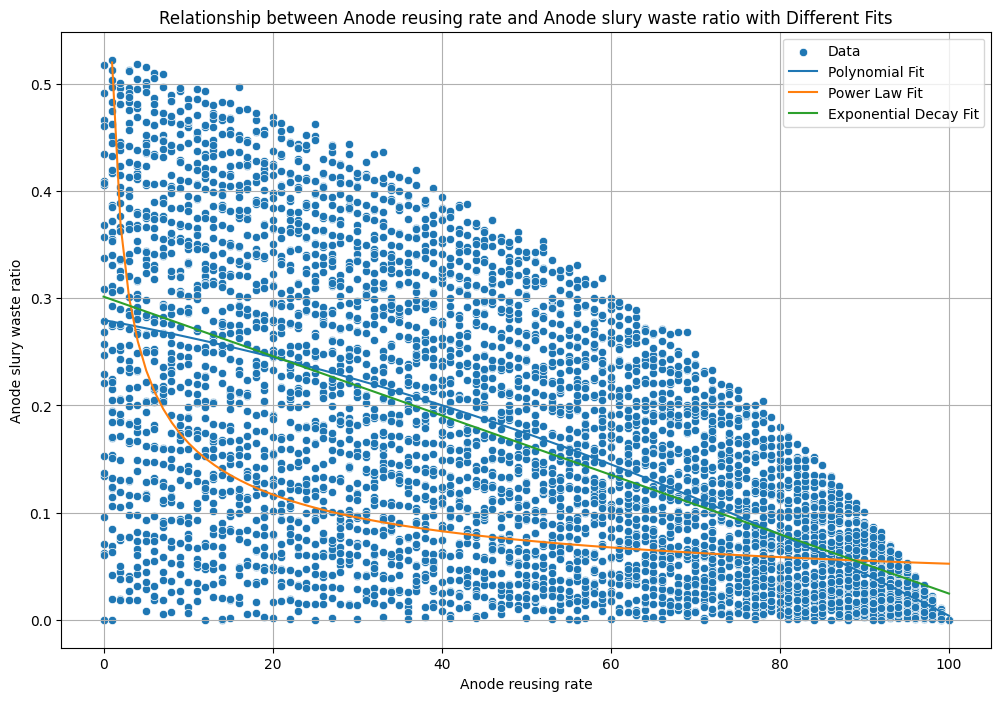


The best fitting function based on R-squared is: Polynomial

The fittest function is: Polynomial
Parameters: [-1.28874756e-05 -1.47134475e-03  2.79696286e-01]


In [42]:
# In[usage]
best_model, params = fit_and_plot_models(df, 'Anode reusing rate', 'Anode slury waste ratio')

if best_model:
    print(f"\nThe fittest function is: {best_model}")
    print(f"Parameters: {params}")
else:
    print("\nNo fittest function found.")